# 13 Rubric additions

Four items the brief names explicitly that the earlier notebooks did not show directly. Nothing here changes the model; every number comes from the same deployed logistic regression on the same temporal folds as Section 11.

| Item | Brief | Output |
|---|---|---|
| 13.1 Confusion matrix at the chosen threshold | Part B5, Section 6 | `reports/13_confusion_matrix.csv`, `figures/13_confusion_matrix.png` |
| 13.2 Business goal as an approval rate | Part A2 | `reports/13_approval_goal.csv` |
| 13.3 PR-AUC, F1 and selection rate by segment | Part D2 | `reports/13_segment_pr_f1.csv` |
| 13.4 Beating the baseline beyond the ±0.0263 noise floor | Section 6 | read from `reports/07_paired_differences.csv` |

The Datasheet (LO5) is in `docs/datasheet.md`.

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, f1_score, confusion_matrix
from src.config import set_seed, FIGURES, DATA_PROCESSED, ROOT
from src import models as M, validation as V
from src.costs import LoanEconomics
set_seed()
econ = LoanEconomics()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
tr = feat[feat.split == "train"].reset_index(drop=True)
cols = M.inputs(M.DEPLOY_FEATURES)
oof, fid, folds = V.cross_validate(M.logreg(numeric=M.DEPLOY_FEATURES, class_weight=None), tr, cols, V.temporal(tr))
ev = tr[fid >= 0].assign(p=oof[fid >= 0], fold=fid[fid >= 0]).reset_index(drop=True)
ev["y"] = ev.target.astype(int)
ev["declined"] = ev.p > econ.threshold
ev["regime"] = np.where(ev.fold >= 3, "Dec 2022 onward", "2022 boom")
print(f"Deployed model, temporal OOF: {len(ev):,} loans, {ev.y.sum()} defaults; threshold {econ.threshold:.4f}")

Deployed model, temporal OOF: 39,894 loans, 655 defaults; threshold 0.0617


## 13.1 Confusion matrix at the cost threshold (decline if P(default) > 0.062)

Positive class = default. "Flagged" means declined (or referred, for thin-file applicants, in the service).

In [2]:
def cm_row(d, label):
    tn, fp, fn, tp = confusion_matrix(d.y, d.declined, labels=[0, 1]).ravel()
    return pd.Series({"loans": len(d), "TP (defaulter declined)": tp, "FN (defaulter approved)": fn,
                      "FP (good borrower declined)": fp, "TN (good borrower approved)": tn,
                      "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                      "F1": f1_score(d.y, d.declined), "approval rate": 1 - d.declined.mean(),
                      "GHS value": econ.gain_good * tn - econ.loss_bad * fn,
                      "GHS per 1,000": (econ.gain_good * tn - econ.loss_bad * fn) / len(d) * 1000}, name=label)

cm = pd.DataFrame([cm_row(ev, "all folds")] + [cm_row(g, r) for r, g in ev.groupby("regime")])
cm.to_csv(ROOT / "reports" / "13_confusion_matrix.csv")
cm.round(3)

,loans,TP (defaulter declined),FN (defaulter approved),FP (good borrower declined),TN (good borrower approved),precision,recall,F1,approval rate,GHS value,"GHS per 1,000"
all folds,39894.0,188.0,467.0,1135.0,38104.0,0.142,0.287,0.190,0.967,775140.0,19429.989
2022 boom,37060.0,50.0,314.0,382.0,36314.0,0.116,0.137,0.126,0.988,788530.0,21277.118
Dec 2022 onward,2834.0,138.0,153.0,753.0,1790.0,0.155,0.474,0.234,0.686,-13390.0,-4724.771


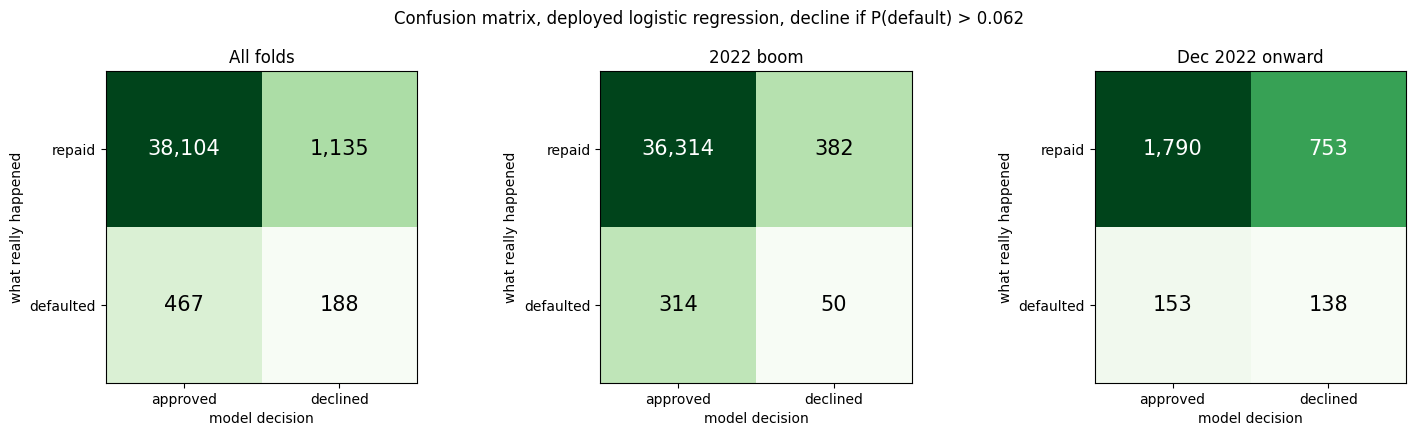

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (label, d) in zip(axes, [("All folds", ev)] + [(r, g) for r, g in ev.groupby("regime")]):
    m = confusion_matrix(d.y, d.declined, labels=[0, 1])
    ax.imshow(np.log1p(m), cmap="Greens")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m[i, j]:,}", ha="center", va="center", fontsize=15,
                    color="white" if (np.log1p(m[i, j]) - np.log1p(m).min()) / (np.log1p(m).max() - np.log1p(m).min()) > 0.5 else "black")
    ax.set_xticks([0, 1], ["approved", "declined"]); ax.set_yticks([0, 1], ["repaid", "defaulted"])
    ax.set_xlabel("model decision"); ax.set_ylabel("what really happened"); ax.set_title(label)
fig.suptitle("Confusion matrix, deployed logistic regression, decline if P(default) > 0.062")
fig.tight_layout(); fig.savefig(FIGURES / "13_confusion_matrix.png", dpi=200); plt.show()

**Reading.** Per regime, the four cells show where the money goes. Each false negative (a defaulter approved) costs about GHS 380, each false positive (a good borrower declined) costs the GHS 25 that loan would have earned. The model accepts many false positives to avoid a few false negatives, which is exactly what the cost matrix asks for.

## 13.2 Business goal as an approval rate (Part A2)

The brief suggests a goal of the form "flag as high-risk above the threshold that keeps expected loss within budget while approving at least X% of applicants". The table shows the approval rate and value for a range of thresholds, so the committee can see the trade-off.

In [4]:
rows = []
for t in [0.02, 0.04, econ.threshold, 0.08, 0.10, 0.15, 0.25, 1.0]:
    dec = ev.p > t
    for label, m in [("all folds", np.ones(len(ev), bool)), ("2022 boom", (ev.regime == "2022 boom").to_numpy()),
                     ("Dec 2022 onward", (ev.regime == "Dec 2022 onward").to_numpy())]:
        y, dd = ev.y.to_numpy()[m], dec.to_numpy()[m]
        tn, fn = ((y == 0) & ~dd).sum(), ((y == 1) & ~dd).sum()
        rows.append({"threshold": round(t, 4), "scope": label, "approval rate": 1 - dd.mean(),
                     "defaults let through": fn / max(y.sum(), 1),
                     "GHS per 1,000": (econ.gain_good * tn - econ.loss_bad * fn) / m.sum() * 1000})
goal = pd.DataFrame(rows)
goal.to_csv(ROOT / "reports" / "13_approval_goal.csv", index=False)
goal.pivot_table(index="threshold", columns="scope", values=["approval rate", "GHS per 1,000"]).round(3)

GHS per 1,000                            approval rate  \
scope         2022 boom Dec 2022 onward  all folds     2022 boom   
threshold                                                          
0.0200        20839.045         878.617  19421.091         0.926   
0.0400        21299.919       -1125.618  19706.848         0.983   
0.0617        21277.118       -4724.771  19429.989         0.988   
0.0800        21305.720       -5714.538  19386.249         0.991   
0.1000        21273.206       -6178.546  19323.081         0.992   
0.1500        21269.968       -7141.849  19251.642         0.994   
0.2500        21264.976       -9036.697  19112.398         0.997   
1.0000        21022.126      -16586.097  18350.504         1.000   

                                     
scope     Dec 2022 onward all folds  
threshold                            
0.0200              0.218     0.876  
0.0400              0.515     0.950  
0.0617              0.686     0.967  
0.0800              0.737     0.973  
0.1000              0.765     0.976  
0.1500              0.818     0.981  
0.2500              0.879     0.988  
1.0000              1.000     1.000

In [5]:
a = goal[(goal.threshold == round(econ.threshold, 4))].set_index("scope")
print(f"At the cost threshold {econ.threshold:.3f} the model approves {a.loc['all folds','approval rate']:.1%} of applicants overall, "
      f"{a.loc['2022 boom','approval rate']:.1%} in the 2022 boom and {a.loc['Dec 2022 onward','approval rate']:.1%} from Dec 2022.")

At the cost threshold 0.062 the model approves 96.7% of applicants overall, 98.8% in the 2022 boom and 68.6% from Dec 2022.


**Business goal (stated).** Decline when P(default) > 0.062, the point where expected value per loan turns negative under our cost matrix. In a stable market this approves almost every applicant; when risk rises the approval rate falls with it. If NkwaPay sets a minimum approval rate for inclusion reasons, the table shows what that costs in cedis per 1,000 applications. Thin-file applicants above the threshold are referred, not declined (Section 11.3), so the share actually turned away is lower than the decline rate here.

## 13.3 PR-AUC, F1 and selection rate by segment (Part D2)

Section 11.2 reported decline rate, precision and recall by segment. The brief also asks for PR-AUC and F1. Selection rate here is the approval rate.

PR-AUC within a segment is computed on scores pooled across folds. Section 7 showed pooling across folds inflates ranking metrics, so compare segments with each other, not with the headline 0.145. A segment needs at least 10 defaults for PR-AUC.

In [6]:
def seg(d):
    y, dec = d.y, d.declined
    return pd.Series({"loans": len(d), "defaults": int(y.sum()), "default rate": y.mean(),
                      "PR-AUC": average_precision_score(y, d.p) if y.sum() >= 10 else np.nan,
                      "PR-AUC / default rate": (average_precision_score(y, d.p) / y.mean()) if y.sum() >= 10 else np.nan,
                      "F1": f1_score(y, dec, zero_division=0), "selection (approval) rate": 1 - dec.mean(),
                      "small sample": y.sum() < 30})

ev["loan_type_g"] = ev.loan_type.where(ev.loan_type.map(ev.loan_type.value_counts()) >= 300, "Other")
ev["size_band"] = pd.qcut(ev.Total_Amount, 5, labels=["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"])
ev["history_band"] = pd.cut(ev.n_prev_loans, [-1, 0, 4, 19, 10_000], labels=["0 earlier loans", "1-4", "5-19", "20+"])
ev["new_vs_repeat"] = np.where(ev.is_new == 1, "New Loan", "Repeat Loan")
segs = {"country": ev.country_id, "regime": ev.regime, "loan type": ev.loan_type_g, "lender": ev.lender_id,
        "New vs Repeat": ev.new_vs_repeat, "loan size band": ev.size_band, "borrowing history": ev.history_band}
st = pd.concat({k: ev.groupby(v, observed=True).apply(seg, include_groups=False) for k, v in segs.items()}, names=["segment", "group"])
st.loc[("all", "all"), :] = seg(ev)
st.to_csv(ROOT / "reports" / "13_segment_pr_f1.csv")
st.round(3)

loans  defaults  default rate  PR-AUC  \
segment           group                                                      
country           Kenya            39894.0     655.0         0.016   0.149   
regime            2022 boom        37060.0     364.0         0.010   0.104   
                  Dec 2022 onward   2834.0     291.0         0.103   0.197   
loan type         Other              794.0     117.0         0.147   0.426   
                  Type_1           36363.0     299.0         0.008   0.029   
                  Type_4             613.0      67.0         0.109   0.188   
                  Type_5             478.0      33.0         0.069   0.067   
                  Type_7            1646.0     139.0         0.084   0.130   
lender            251804            2452.0     197.0         0.080   0.096   
                  267277             260.0      72.0         0.277   0.582   
                  267278           37182.0     386.0         0.010   0.080   
New vs Repeat     New Loan           205.0      22.0         0.107   0.350   
                  Repeat Loan      39689.0     633.0         0.016   0.143   
loan size band    Q1 smallest       7981.0     121.0         0.015   0.051   
                  Q2                7978.0      55.0         0.007   0.051   
                  Q3                7977.0     131.0         0.016   0.099   
                  Q4                7979.0     100.0         0.013   0.067   
                  Q5 largest        7979.0     248.0         0.031   0.268   
borrowing history 0 earlier loans   1781.0     195.0         0.109   0.286   
                  1-4               4808.0     189.0         0.039   0.137   
                  5-19             18121.0     226.0         0.012   0.055   
                  20+              15184.0      45.0         0.003   0.013   
all               all              39894.0     655.0         0.016   0.149   

                                   PR-AUC / default rate     F1  \
segment           group                                           
country           Kenya                            9.074  0.190   
regime            2022 boom                       10.538  0.126   
                  Dec 2022 onward                  1.920  0.234   
loan type         Other                            2.888  0.351   
                  Type_1                           3.567  0.000   
                  Type_4                           1.724  0.203   
                  Type_5                           0.977  0.105   
                  Type_7                           1.535  0.113   
lender            251804                           1.192  0.139   
                  267277                           2.101  0.443   
                  267278                           7.723  0.142   
New vs Repeat     New Loan                         3.266  0.273   
                  Repeat Loan                      8.984  0.185   
loan size band    Q1 smallest                      3.355  0.013   
                  Q2                               7.325  0.093   
                  Q3                               6.042  0.121   
                  Q4                               5.331  0.135   
                  Q5 largest                       8.620  0.268   
borrowing history 0 earlier loans                  2.610  0.270   
                  1-4                              3.487  0.168   
                  5-19                             4.437  0.106   
                  20+                              4.429  0.033   
all               all                              9.074  0.190   

                                   selection (approval) rate small sample  
segment           group                                                    
country           Kenya                                0.967        False  
regime            2022 boom                            0.988        False  
                  Dec 2022 onward                      0.686        False  
loan type         Other       

**Reading.** The ratio column (PR-AUC divided by the segment's default rate) is the fairer comparison, because PR-AUC rises with the base rate. Country has a single row because every labelled loan is Kenyan; Ghana's predicted decline rate (22%) is in Section 10 and is not a performance metric.

## 13.4 Beating the baseline beyond the noise floor (±0.0263)

The brief gives a noise floor of ±0.0263 at leaderboard size. Our own paired customer bootstrap (Section 7) gives intervals on the actual differences, which is the stricter test. Both are read below.

In [7]:
pdiff = pd.read_csv(ROOT / "reports" / "07_paired_differences.csv")
sel = pdiff[pdiff.metric.isin(["F1 @ 0.062", "PR-AUC"])].copy()
sel["beyond ±0.0263"] = sel["mean"].abs() > 0.0263
sel["interval excludes 0"] = (sel.lower > 0) | (sel.upper < 0)
sel[["comparison", "scope", "metric", "mean", "lower", "upper", "beyond ±0.0263", "interval excludes 0", "verdict"]].round(4)

,comparison,scope,metric,mean,lower,upper,beyond ±0.0263,interval excludes 0,verdict
0,logreg - baseline,all folds,F1 @ 0.062,0.2015,0.1780,0.2240,True,True,logreg better
2,logreg - baseline,all folds,PR-AUC,0.0978,0.0734,0.1226,True,True,logreg better
4,logreg - lgbm_shallow,all folds,F1 @ 0.062,0.0164,-0.0029,0.0323,False,False,not distinguishable
6,logreg - lgbm_shallow,all folds,PR-AUC,0.0116,-0.0050,0.0281,False,False,not distinguishable
8,logreg - baseline,Dec 2022 on,F1 @ 0.062,0.2359,0.2028,0.2675,True,True,logreg better
10,logreg - baseline,Dec 2022 on,PR-AUC,0.0998,0.0647,0.1394,True,True,logreg better
12,logreg - lgbm_shallow,Dec 2022 on,F1 @ 0.062,0.0125,-0.0096,0.0353,False,False,not distinguishable
14,logreg - lgbm_shallow,Dec 2022 on,PR-AUC,0.0377,0.0080,0.0697,True,True,logreg better


**Reading.** Logistic regression beats the baseline by about 0.20 in F1 and 0.10 in PR-AUC, far beyond ±0.0263, and the bootstrap interval excludes zero. Against shallow LightGBM the overall F1 and PR-AUC differences are about 0.01 to 0.02, inside the noise floor, so the two cannot be told apart overall. After Dec 2022 the PR-AUC gap (0.038) exceeds the floor and its interval excludes zero.